# Ataques Adversariais: Comprometendo Sistemas Baseados em Machine Learning

## Importações

In [1]:
!pip install gdown

import gdown

  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached PySocks-1.7.1-py3-none-any.whl.metadata (13 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
Using cached PySocks-1.7.1-py3-none-any.whl (16 kB)

   ---------------------------------------- 0/4 [soupsieve]
   ---------- ----------------------------- 1/4 [PySocks]
   -------------------- ------------------- 2/4 [beautifulsoup4]
   -------------------- ------------------- 2/4 [beautifulsoup4]
   -------------------- ------------------- 2/4 [beautifulsoup4]
   -------------------- ------------------- 2/4 [beautifulsoup4]
   ------------------------------ --------- 3/4 [gdown]
   ------------------------------ --------- 3/4 [gdown]
   ---------------------------------------- 4/4 [gdown]




[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from PIL import Image
import matplotlib.pyplot as plt
import os
import random
import numpy as np
import zipfile
import shutil

## Carregamento de Dados

In [4]:
!gdown --folder https://drive.google.com/drive/folders/1ZJIITWgAplI4_Aohj_Hw5Nuz9KEw_ZhM

Processing file 1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp cats_dogs_small.zip
Processing file 1eSkfzfI50ayZJvMPZp2XPCSXqt4Qu1JC glasses_no_glasses.zip
Processing file 1VNwAt5AHWoKXuwhCrE1uiTpAk_rKQFBh mask_no_mask.zip


Using cookies from C:\Users\gabri\.cache/gdown/cookies.txt
Retrieving folder contents
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp
From (redirected): https://drive.google.com/uc?id=1gVmNAc_uvFR7ujpd4TAZQ533yr-X1dmp&confirm=t&uuid=4c1c260a-7191-4e8c-9813-b6660feba865
To: c:\Projects\26.2\TADI\intrusion_detection_studies\Data\cats_dogs_small.zip

  0%|          | 0.00/32.3M [00:00<?, ?B/s]
  2%|▏         | 524k/32.3M [00:10<10:50, 48.8kB/s]
  3%|▎         | 1.05M/32.3M [00:18<08:44, 59.6kB/s]
  5%|▍         | 1.57M/32.3M [00:23<06:54, 74.1kB/s]
  6%|▋         | 2.10M/32.3M [00:26<05:24, 93.2kB/s]
  8%|▊         | 2.62M/32.3M [00:39<07:46, 63.6kB/s]
 10%|▉         | 3.15M/32.3M [00:42<05:58, 81.2kB/s]
 11%|█▏        | 3.67M/32.3M [00:44<04:38, 103kB/s] 
 13%|█▎        | 4.19M/32.3M [00:46<03:28, 135kB/s]
 15%|█▍        | 4.72M/32.3M [

In [2]:
data_path = "data/"

zip_files = [f for f in os.listdir(data_path) if f.endswith(".zip")]

print("Datasets disponíveis:\n")
for i, file in enumerate(zip_files, 1):
    print(f"{i} - {file}")

choice = input("\nDigite o número do dataset: ")

try:
    choice = int(choice)
    selected_zip = zip_files[choice - 1]
except:
    raise ValueError("Opção inválida!")

zip_path = os.path.join(data_path, selected_zip)

extract_path = os.path.join(data_path, selected_zip.replace(".zip", ""))
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

subdirs = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]

if len(subdirs) == 1:
    inner_path = os.path.join(extract_path, subdirs[0])

    for item in os.listdir(inner_path):
        shutil.move(os.path.join(inner_path, item), extract_path)

    os.rmdir(inner_path)

print(f"\nDataset escolhido: {selected_zip}")
print(f"Extraído em: {extract_path}")

Datasets disponíveis:

1 - cats_dogs_small.zip
2 - glasses_no_glasses.zip
3 - mask_no_mask.zip

Dataset escolhido: glasses_no_glasses.zip
Extraído em: data/glasses_no_glasses


In [3]:
data_dir = extract_path

In [4]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 316 files belonging to 2 classes.
Using 253 files for training.
Using 63 files for validation.


In [5]:
print(train_ds.class_names)

['glasses', 'no_glasses']


## Modelo de Classificação

In [6]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')
base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [7]:
model.fit(train_ds, validation_data=val_ds, epochs=3)

Epoch 1/3


c:\PythonEnvs\ml-ai\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 12s 567ms/step - accuracy: 0.5415 - loss: 0.7327 - val_accuracy: 0.6032 - val_loss: 0.6769
Epoch 2/3
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 182ms/step - accuracy: 0.6324 - loss: 0.6013 - val_accuracy: 0.8571 - val_loss: 0.5089
Epoch 3/3
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 183ms/step - accuracy: 0.9486 - loss: 0.4724 - val_accuracy: 1.0000 - val_loss: 0.4167


In [8]:
model.evaluate(val_ds)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 1.0000 - loss: 0.4167


[0.4166660010814667, 1.0]

## Mostrando as imagens

In [9]:
class_names = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]

paths = []

class_names = sorted(class_names)

for class_name in class_names:
    class_dir = os.path.join(data_dir, class_name)

    images = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not images:
        continue

    chosen = random.choice(images)
    full_path = os.path.join(class_dir, chosen)

    paths.append(full_path)

if len(paths) >= 2:
    path_class1 = paths[0]
    path_class2 = paths[1]

print("Classe 1:", path_class1)
print("Classe 2:", path_class2)

Classe 1: data/glasses_no_glasses\glasses\110.jpg
Classe 2: data/glasses_no_glasses\no_glasses\114.jpg


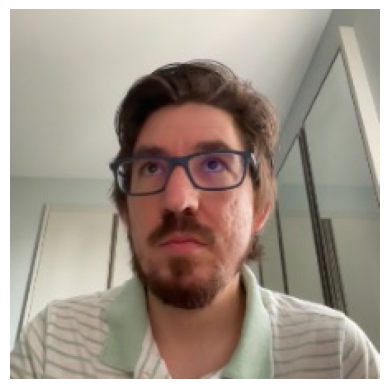

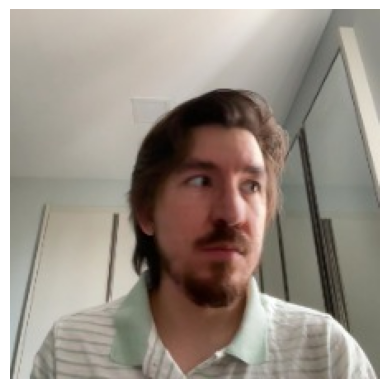

In [10]:
img_cat = Image.open(path_class1)
plt.imshow(img_cat)
plt.axis('off')
plt.show()

img_dog = Image.open(path_class2)
plt.imshow(img_dog)
plt.axis('off')
plt.show()

## Realizando a inferência

In [11]:
def predict_image(path, model, class_names):
    img = tf.keras.utils.load_img(path, target_size=(160,160))
    img = tf.keras.utils.img_to_array(img)

    img = tf.expand_dims(img, axis=0)

    pred = model.predict(img, verbose=0)[0][0]

    pred_class = int(pred >= 0.5)
    class_name = class_names[pred_class]

    confidence = pred if pred_class == 1 else 1 - pred

    return img, pred, class_name, confidence

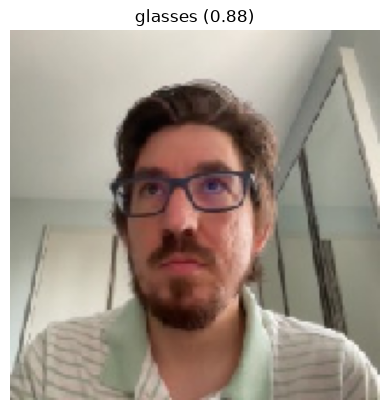

In [12]:
img, pred, classe, conf = predict_image(path_class1, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

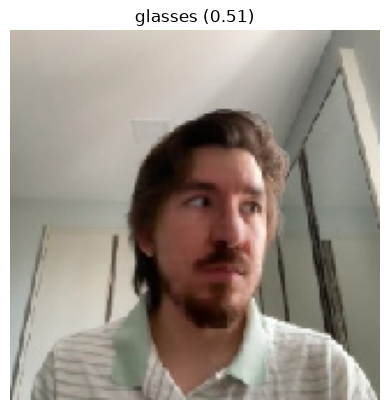

In [13]:
img, pred, classe, conf = predict_image(path_class2, model, class_names)

plt.imshow(img[0].numpy().astype("uint8"))
plt.title(f"{classe} ({conf:.2f})")
plt.axis('off')
plt.show()

# BlackBox - Adversarial Attacks

## Square Attack

O square attack é um ataque black-box, ou seja, não necessita de acesso à arquitetura, parâmetros e dados de treino para ser executado. O Square Attack precisa apenas de acesso ao score das classes calculado pelo classificador para produzir exemplos adversariais por meio de um processo iterativo.

 O ataque foi pensado para ser utilizado no cenário de redes neurais profundas que têm como entrada imagens, e este fato é importante pois explica o raciocínio por trás do ataque. As redes neurais convolucionais varrem uma imagem, a processando em pequenas janelas de formato quadrado, assim o Square Attack busca perturbar essas redes introduzindo perturbações em forma de quadrados de tamanho e intensidade variados.

Podemos descrever o funcionamento do ataque nos seguintes passos:

1. Gerar uma perturbação aleatória em forma de quadrado com uma localização e intensidade aleatória;
2. Aplicar esta perturbação à imagem;
3. Obter os scores da imagem perturbada;
4. Caso o score da classe correta diminua, manter essa perturbação, caso contrário descartar;
5. Repetir o processo até obter um exemplo adversarial ou atingir um número limite de iterações.

Como parâmetros do Square Attack, temos:

1. eps: Controlar a intensidade da perturbação;
2. initial_p: Controla o tamanho inicial do quadrado, sendo que o tamanho dos quadrados gerados é reduzido com o passar das iterações;
3. n_iters: Quantidade de chamadas ao modelo que serão executadas;
4. initialization: Se uma inicialização será aplicada à imagem.

Assim, alterando os parâmetros é possível obter um ataque que de maneira veloz gere perturbações adversariais bem perceptíveis, ou um ataque mais discreto que precisa de mais iterações para gerar perturbações.

### Classe que implementa o Square Attack.

In [9]:
# adaptado de https://github.com/max-andr/square-attack
# artigo: https://arxiv.org/abs/1912.00049

class SquareAttack:
    def __init__(self, eps, n_iters, initial_p, initialization=True):
        self.eps = eps
        self.n_iters = n_iters
        self.initial_p = initial_p
        self.initialization = initialization

    def p_selection(self, p_init, it, n_iters):
        it = int(it / n_iters * 10000)
        if 10 < it <= 50: return p_init / 2
        elif 50 < it <= 200: return p_init / 4
        elif 200 < it <= 500: return p_init / 8
        elif 500 < it <= 1000: return p_init / 16
        elif 1000 < it <= 2000: return p_init / 32
        elif 2000 < it <= 4000: return p_init / 64
        elif 4000 < it <= 6000: return p_init / 128
        elif 6000 < it <= 8000: return p_init / 256
        elif 8000 < it <= 10000: return p_init / 512
        else: return p_init

    def apply(self, model, image, y):
        if len(image.shape) == 3:
            image = tf.expand_dims(image, 0)

        image = tf.cast(image, tf.float32).numpy()
        _, h, w, c = image.shape
        n_features = c * h * w
        min_val, max_val = 0.0, 255.0

        X = image

        if self.initialization:
            init_delta = np.random.choice([-self.eps, self.eps], size=[1, h, w, c])
            X_best = np.clip(X + init_delta, min_val, max_val)
        else:
            X_best = np.copy(X)

        pert = X_best - X

        pred_prob = model.predict(X_best, verbose=0)[0][0]
        y_pred = 1 if pred_prob >= 0.5 else 0

        if y_pred != y:
            return 0, X_best, pert

        loss_min = pred_prob if y == 1 else (1.0 - pred_prob)

        for i_iter in range(self.n_iters):
            X_curr = X
            X_best_curr = X_best
            delta = X_best_curr - X_curr

            p = self.p_selection(self.initial_p, i_iter, self.n_iters)
            s = int(round(np.sqrt(p * n_features / c)))
            s = min(max(s, 1), h - 1)

            center_h = np.random.randint(0, max(h - s, 1))
            center_w = np.random.randint(0, max(w - s, 1))

            delta_new = np.copy(delta)

            delta_new[:, center_h:center_h+s, center_w:center_w+s, :] = np.random.choice(
                [-self.eps, self.eps], size=[1, 1, 1, c]
            )

            X_new = np.clip(X_curr + delta_new, min_val, max_val)

            pred_prob = model.predict(X_new, verbose=0)[0][0]
            y_pred = 1 if pred_prob >= 0.5 else 0
            score = pred_prob if y == 1 else (1.0 - pred_prob)

            if y_pred != y:
                return i_iter + 1, X_new, delta_new

            if score < loss_min:
                loss_min = score
                X_best = X_new
                pert = delta_new

        return self.n_iters, X_best, pert

Vamos observar a relação entre imperceptibilidade e velocidade do ataque, para tanto vamos definir duas configurações de parâmetros diferentes. Uma vai produzir perturbações mais perceptíveis que enganam o classificador mais rapidamente. A outra irá produzir perturbações mais discretas que demoram mais para apresentar efeito.

Configuração Discreta
*   eps: 8.9
*   initial_p: 0.5
*   Inicialização: Falso

Configuração Rápida
*   eps: 15.3
*   initial_p: 0.7
*   Inicialização: Verdadeiro

## Atividade 1: Gerando exemplos adversariais com o Square Attack

### Square Attack - Configuração Discreta

#### Variação Paramétrica

1. 
    - eps: 15
    - n_iters: 300
    - initial_p: 1.0
    - confiança: 0.5027
2. 
    - eps: 5
    - n_iters: 10000
    - initial_p: 0.2
    - confiança: 0.5268
3. 
    - eps: 5.0
    - n_iters: 10000
    - initial_p: 0.05
    - confiança: 0.5268
4. 
    - eps: 3.5
    - n_iters: 1000
    - initial_p: 0.03
    - confiança: 0.5001
    - iterações: 540

#### Construindo a Exemplo Adversarial

In [10]:
def get_n_inputs(val_ds, desired_class, n=1):
    x_inputs = []
    y_trues = []
    for images, labels in val_ds.unbatch():
        if labels.numpy() == desired_class:
            x_input = tf.cast(tf.expand_dims(images, 0), tf.float32)
            y_true_ch = tf.cast(tf.reshape([labels], [-1]), tf.int32)
            x_inputs.append(x_input)
            y_trues.append(y_true_ch)
            if len(x_inputs) == n:
                return (x_inputs, y_trues)
    return (x_inputs, y_trues)

In [19]:
# For reproductibility
np.random.seed(19)

EPS_SQATK_1 = 1.5
N_IT_SQATK_1 = 500
INIT_P_SQATK_1 = 0.01
INITIALIZATION_SQATK_1 = False # Exemplo discreto

x_inputs, y_trues = get_n_inputs(val_ds, desired_class=1, n=1)
results = []

# Craft adversarial sample
for x_input, y_true in zip(x_inputs, y_trues):
    original_image = x_input[0].numpy()
    true_label = y_true[0].numpy()

    attack = SquareAttack(eps=EPS_SQATK_1, n_iters=N_IT_SQATK_1, initial_p=INIT_P_SQATK_1, initialization=INITIALIZATION_SQATK_1)
    iters, adv_img, pert = attack.apply(model, original_image, true_label)
    results.append((iters, adv_img, pert))
    print(f"Número de iterações necessárias: {iters}")

Número de iterações necessárias: 500


#### Realizando a classificação do exemplo adversarial

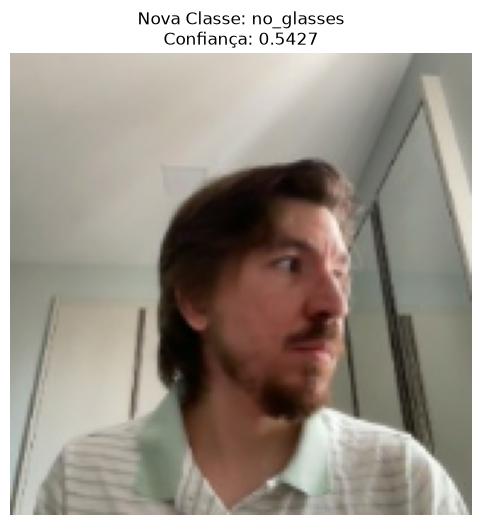

In [20]:
class_names = train_ds.class_names

pred_prob = model.predict(adv_img, verbose=0)[0][0]

idx = int(pred_prob >= 0.5)
nova_classe = class_names[idx]

plt.figure(figsize=(6, 6))

img_para_mostrar = tf.cast(adv_img[0], tf.uint8)
plt.imshow(img_para_mostrar)

plt.title(
    f"Nova Classe: {nova_classe}\nConfiança: {pred_prob:.4f}")

plt.axis('off')
plt.show()

#### Exibindo a perturbação adversarial

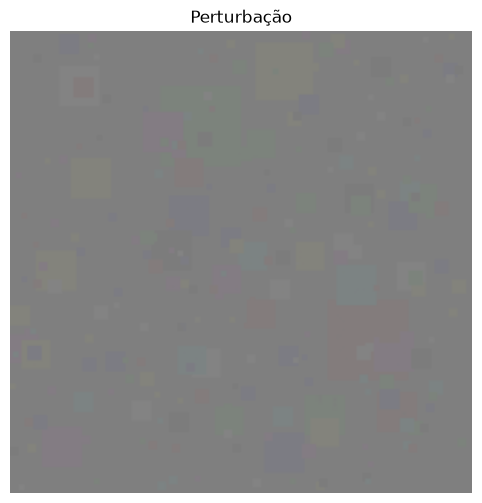

In [21]:
adv_f = adv_img[0].astype('float32')
org_f = original_image.astype('float32')

perturbacao_real = adv_f - org_f
img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))

plt.imshow(img_visualizacao, cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.title("Perturbação")
plt.show()

### Square Attack - Configuração Rápida

#### Variação Paramétrica

Classe 1 -> 0

1. 
    - eps: 3.5
    - n_iters: 1000
    - initial_p: 0.03
    - confiança: 0.5001
    - iterações: 138
1. 
    - eps: 2.5
    - n_iters: 1000
    - initial_p: 0.03
    - confiança: 0.5001
    - iterações: 373

#### Construindo o Exemplo Adversarial

In [ ]:
np.random.seed(19)

EPS_SQATK_2 = 2.5
N_IT_SQATK_2 = 1000
INIT_P_SQATK_2 = 0.03
INITIALIZATION_SQATK_2 = True  # Exemplo rápido

x_inputs, y_trues = get_n_inputs(val_ds, desired_class=1, n=1)
results = []

# Craft adversarial sample
for x_input, y_true in zip(x_inputs, y_trues):
    original_image = x_input[0].numpy()
    true_label = y_true[0].numpy()

    attack = SquareAttack(eps=EPS_SQATK_2, n_iters=N_IT_SQATK_2, initial_p=INIT_P_SQATK_2, initialization=INITIALIZATION_SQATK_2)
    iters, adv_img, pert = attack.apply(model, original_image, true_label)
    results.append((iters, adv_img, pert))
    print(f"Número de iterações necessárias: {iters}")

Número de iterações necessárias: 373


#### Realizando a classificação do exemplo adversarial

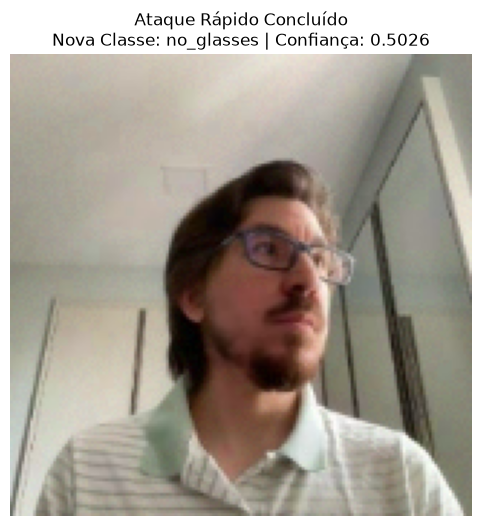

In [23]:
class_names = train_ds.class_names

pred_prob = model.predict(adv_img, verbose=0)[0][0]

idx = int(pred_prob >= 0.5)

nova_classe = class_names[idx]

conf = pred_prob if idx == 1 else (1 - pred_prob)

plt.figure(figsize=(6, 6))

img_para_mostrar = tf.cast(adv_img[0], tf.uint8)
plt.imshow(img_para_mostrar)

plt.title(
    f"Ataque Rápido Concluído\nNova Classe: {nova_classe} | Confiança: {conf:.4f}")

plt.axis('off')
plt.show()

#### Exibindo a perturbação adversarial

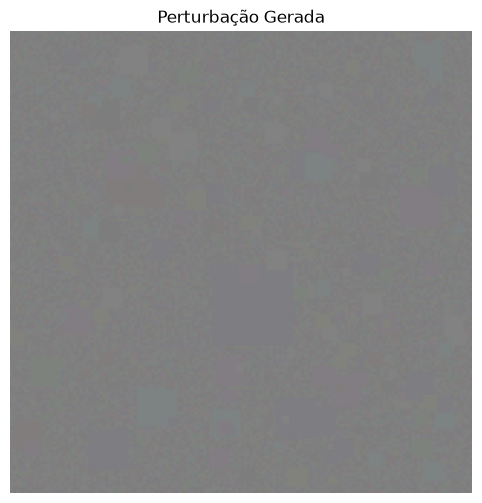

In [25]:
# # Get and print adversarial perturbation
adv_f = adv_img[0].astype('float32')
org_f = original_image.astype('float32')

perturbacao_real = adv_f - org_f
img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))
plt.imshow(np.clip(img_visualizacao, 0, 1), cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.title("Perturbação Gerada")
plt.show()

## SimBA

O simBA (Simple Black Box Attack) também é um ataque iterativo baseado em score, com algumas diferenças em relação ao Square Attack. A intuição do simBA é baseada em obter ruídos retirados de direções ortnormais e então tentar adcionar esses ruídos à imagem. Um exemplos do que são essas direções ortonormais, é o espaço dos pixels da imagem, ou seja, cada perturbação seria aplicada à um único pixel.

A implementação adaptada abaixo leva em conta que para imagens de tamanho razoável, a alteração de um único pixel não é capaz de produzir variações grandes o suficiente no score. Assim a solução é utilizar blocos de pixels maiores como direção ortornomal.

Outro ponto, é que foi observado experimentalmente que perturbações em padrão de baixa frequência tem tendência adversarial em comparação à um padrão uniforme ou completamente aleatório. Portanto os padrões gerados são baseados em perturbações de baixa frequência.

Assim podemos descrever o algoritmo do simBA:

1. Retirar um vetor de uma base ortonormal;
2. Adcionar este vetor à imagem atual;
3. Caso o score da classe correta diminua, adotar esta perturbação;
4. Caso contrário, experimentar subtrair o vetor da imagem, caso o score diminua, adotar esta perturbação;
5. Repetir o processo até obter uma imagem adversarial ou atingir um limite de iterações.

Os parâmetros do simBA são:

1. epsilon: intensidade da perturbação.
2. block_size: tamanho do bloco a ser aplicado cada perturbação.
3. n_iters: número de iterações.

### Classe que implementa o SimBA

In [26]:
# adaptado de https://github.com/cg563/simple-blackbox-attack/blob/master/simba.py
# artigo: https://arxiv.org/abs/1905.07121

from scipy.fftpack import dctn, idctn

class SimBA:
    def __init__(self, epsilon, n_iters):
        self.epsilon = epsilon
        self.n_iters = n_iters

    def apply(self, image, y, model, block_size=8):
        if len(image.shape) == 3:
            image = tf.expand_dims(image, 0)

        image = tf.cast(image, tf.float32).numpy()
        _, h, w, c = image.shape

        new_h = h + block_size - h % block_size
        new_w = w + block_size - w % block_size
        resized_x = np.zeros((1, new_h, new_w, c))
        resized_x[:, :h, :w, :] = image

        min_val, max_val = 0.0, 255.0

        n_dims = int((new_h * new_w * c) / (block_size ** 2))
        perm = np.random.permutation(n_dims)

        pred_prob = model.predict(image, verbose=0)[0][0]
        y_pred = 1 if pred_prob >= 0.5 else 0

        if y_pred != y:
             return 0, image, np.zeros_like(image)

        score = pred_prob if y == 1 else (1.0 - pred_prob)
        loss_min = score
        x_best = resized_x.copy()

        n_queries = 1

        for i in range(min(n_dims, self.n_iters)):
            diff = np.zeros((block_size, block_size))

            pert = np.random.choice([-self.epsilon, self.epsilon], size=4)
            diff[:2, :2] = np.reshape(pert, (2, 2))
            noise_block = idctn(diff, norm='ortho')

            index = perm[i]
            channel_index = int(index // ((new_h * new_w) / (block_size ** 2)))
            remaining_index = index - channel_index * ((new_h * new_w) / (block_size ** 2))
            row_index = int(remaining_index // (new_w / block_size))
            col_index = int(remaining_index - row_index * (new_w / block_size))

            x_new = x_best.copy()

            area = x_new[:, row_index*block_size:(row_index+1)*block_size, col_index*block_size:(col_index+1)*block_size, channel_index]
            x_new[:, row_index*block_size:(row_index+1)*block_size, col_index*block_size:(col_index+1)*block_size, channel_index] = np.clip(area + noise_block, min_val, max_val)

            x_new_cropped = x_new[:, :h, :w, :]

            pred_prob = model.predict(x_new_cropped, verbose=0)[0][0]
            y_pred = 1 if pred_prob >= 0.5 else 0
            score = pred_prob if y == 1 else (1.0 - pred_prob)

            if y_pred != y:
                pert_final = x_new_cropped - image
                return n_queries, x_new_cropped, pert_final

            n_queries += 1

            if score < loss_min:
                x_best = x_new.copy()
                loss_min = score
            else:
                if n_queries >= self.n_iters:
                    break

                x_new = x_best.copy()
                area = x_new[:, row_index*block_size:(row_index+1)*block_size, col_index*block_size:(col_index+1)*block_size, channel_index]
                x_new[:, row_index*block_size:(row_index+1)*block_size, col_index*block_size:(col_index+1)*block_size, channel_index] = np.clip(area - noise_block, min_val, max_val)

                x_new_cropped = x_new[:, :h, :w, :]

                pred_prob = model.predict(x_new_cropped, verbose=0)[0][0]
                y_pred = 1 if pred_prob >= 0.5 else 0
                score = pred_prob if y == 1 else (1.0 - pred_prob)

                if y_pred != y:
                    pert_final = x_new_cropped - image
                    return n_queries, x_new_cropped, pert_final

                n_queries += 1

                if score < loss_min:
                    x_best = x_new.copy()
                    loss_min = score

            if n_queries >= self.n_iters:
                break

        adv_img_final = x_best[:, :h, :w, :c]
        pert_final = adv_img_final - image

        return self.n_iters, adv_img_final, pert_final

## Atividade 2: Gerando exemplos adversariais com o SimBA

### Criando o Exemplo Adversarial

In [ ]:
np.random.seed(19)

EPS_SQATK = 3.5
N_IT_SQATK = 1000
INIT_P_SQATK = 0.03
INITIALIZATION_SQATK = False # Exemplo discreto

x_inputs, y_trues = get_n_inputs(val_ds, desired_class=0, n=1)
results = []

# Craft adversarial sample
for x_input, y_true in zip(x_inputs, y_trues):
    original_image = x_input[0].numpy()
    true_label = y_true[0].numpy()

    attack = SquareAttack(eps=EPS_SQATK, n_iters=N_IT_SQATK, initial_p=INIT_P_SQATK, initialization=INITIALIZATION_SQATK)
    iters, adv_img, pert = attack.apply(model, original_image, true_label)
    results.append((iters, adv_img, pert))
    print(f"Número de iterações necessárias: {iters}")

Número de iterações necessárias: 59


### Realizando a classificação do exemplo adversarial

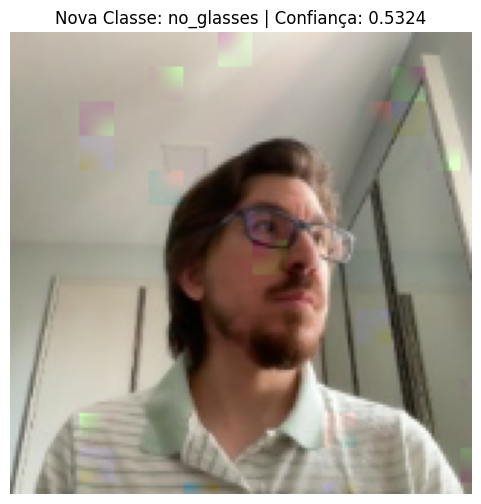

In [33]:
class_names = train_ds.class_names

pred_prob = model.predict(adv_img, verbose=0)[0][0]

idx = int(pred_prob >= 0.5)

nova_classe = class_names[idx]

conf = pred_prob if idx == 1 else (1 - pred_prob)

plt.figure(figsize=(6, 6))
img_para_mostrar = tf.cast(adv_img[0], tf.uint8)
plt.imshow(img_para_mostrar)

plt.title(
    f"Nova Classe: {nova_classe} | Confiança: {conf:.4f}")

plt.axis('off')
plt.show()

### Exibindo o ruído adicionado

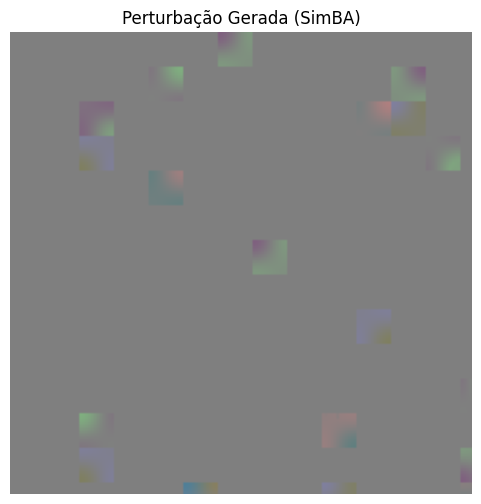

In [34]:
adv_f = adv_img[0].astype('float32')
org_f = original_image.numpy().astype('float32')

perturbacao_real = adv_f - org_f
img_visualizacao = (perturbacao_real / 255.0) + 0.5

vmax = 0.1
vmin = -vmax

plt.figure(figsize=(6, 6))
plt.imshow(np.clip(img_visualizacao, 0, 1), cmap='gray', vmin=vmin, vmax=vmax)
plt.axis('off')
plt.title("Perturbação Gerada (SimBA)")
plt.show()